
# Product Review Classification Using Sentiment Analysis and NLP Models

## 1. Data Exploration

**Objective:** Inspect the Amazon product-review dataset, understand its structure, validate the sentiment labels, and identify data-quality issues before preprocessing and model training.

### Dataset
- Source: Amazon product reviews dataset downloaded from Zenodo
- File: `data/raw/amazon_reviews.csv`
- Task: Three-class sentiment classification
- Classes: Positive, Neutral, Negative

### Planned rating-to-sentiment mapping
- Ratings 1–2: Negative
- Rating 3: Neutral
- Ratings 4–5: Positive



In [14]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "amazon_reviews.csv"

print("Project root:", PROJECT_ROOT)
print("Dataset exists:", DATA_PATH.exists())

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Project root: c:\Users\91886\Python\product-review-sentiment
Dataset exists: True
Dataset shape: (60889, 6)


,Unique_ID,Category,Review_Header,Review_text,Rating,Own_Rating
0,136040,smartTv,Nice one,I liked it,5,Positive
1,134236,mobile,Huge battery life with amazing display,I bought the phone on Amazon and been using my...,5,Positive
2,113945,books,Four Stars,"Awesome book at reasonable price, must buy ......",4,Positive
3,168076,smartTv,Nice quality,good,5,Positive
4,157302,books,Nice book,"The book is fine,not bad,contains nice concept...",3,Neutral


In [16]:
# 1. Inspect column names
print("Columns:")
print(df.columns.tolist())

# 2. Inspect data types
print("\nData types:")
display(df.dtypes.to_frame(name="Data Type"))

# 3. Check dataset size
print(f"\nNumber of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# 4. View a sample of reviews
display(df[["Category", "Review_Header", "Review_text", "Rating", "Own_Rating"]].head(10))

Columns:
['Unique_ID', 'Category', 'Review_Header', 'Review_text', 'Rating', 'Own_Rating']

Data types:


,Data Type
Unique_ID,int64
Category,str
Review_Header,str
Review_text,str
Rating,int64
Own_Rating,str



Number of rows: 60,889
Number of columns: 6


,Category,Review_Header,Review_text,Rating,Own_Rating
0,smartTv,Nice one,I liked it,5,Positive
1,mobile,Huge battery life with amazing display,I bought the phone on Amazon and been using my...,5,Positive
2,books,Four Stars,"Awesome book at reasonable price, must buy ......",4,Positive
3,smartTv,Nice quality,good,5,Positive
4,books,Nice book,"The book is fine,not bad,contains nice concept...",3,Neutral
5,smartTv,Nice tv,Nice tv and pic quality .good custmer srrvice ...,5,Positive
6,smartTv,Beauty and the Beast,The iPhone 7 is legitimately among the most in...,5,Positive
7,mobile,"20000 mAH, what more you need","20000 mAH, what more you need. Super product",5,Positive
8,mobile,Need more good quality,The company should give more Bettany backup an...,2,Negative
9,mobile accessories,Good phone,Very good phone,5,Positive


,Number of Reviews
Own_Rating,
Positive,47436
Negative,9087
Neutral,4366


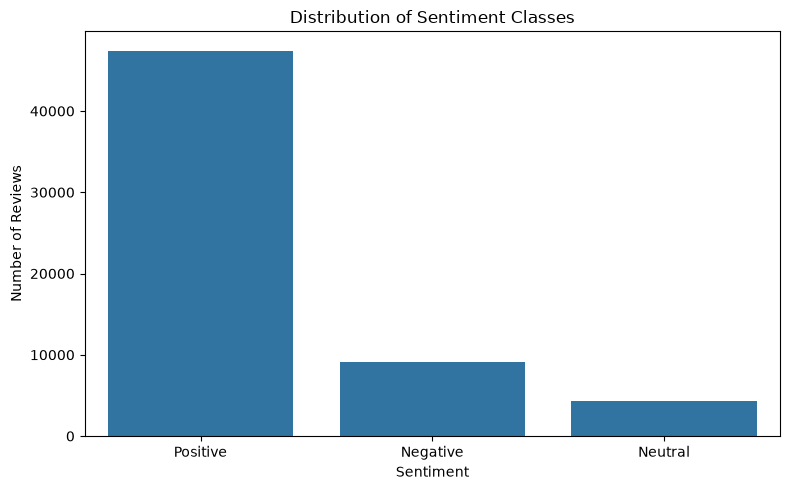

,Percentage (%)
Own_Rating,
Positive,77.91
Negative,14.92
Neutral,7.17


In [17]:
# Count reviews in each sentiment class
sentiment_counts = df["Own_Rating"].value_counts()

display(sentiment_counts.to_frame(name="Number of Reviews"))

# Visualize the class distribution
plt.figure(figsize=(8, 5))
sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

# Calculate percentages
sentiment_percentages = (
    df["Own_Rating"].value_counts(normalize=True) * 100
)

display(sentiment_percentages.round(2).to_frame(name="Percentage (%)"))

In [18]:
# Count missing values in each column
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": (
        df.isna().mean() * 100
    ).round(3)
})

display(missing_summary)

# Check empty or whitespace-only text
for column in ["Review_Header", "Review_text"]:
    empty_mask = (
        df[column].isna()
        | df[column].astype("string").str.strip().eq("").fillna(False)
    )
    print(f"{column}: {empty_mask.sum():,} empty values")

# Check exact duplicate rows
print(f"\nExact duplicate rows: {df.duplicated().sum():,}")

# Check repeated review IDs
print(f"Unique IDs: {df['Unique_ID'].nunique():,}")
print(f"Total rows: {len(df):,}")

,Missing Count,Missing Percentage (%)
Unique_ID,0,0.000
Category,0,0.000
Review_Header,5,0.008
Review_text,32,0.053
Rating,0,0.000
Own_Rating,0,0.000


Review_Header: 5 empty values
Review_text: 32 empty values

Exact duplicate rows: 0
Unique IDs: 60,889
Total rows: 60,889


In [19]:
# Define the proposed rating-to-sentiment mapping
rating_to_sentiment = {
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive",
}

# Derive expected labels from the numerical ratings
expected_labels = df["Rating"].map(rating_to_sentiment)

# Normalize the existing labels for comparison
provided_labels = df["Own_Rating"].str.strip().str.title()

# Identify disagreements
mismatch_mask = (
    expected_labels.notna()
    & provided_labels.notna()
    & expected_labels.ne(provided_labels)
)

print("Rating values:", sorted(df["Rating"].dropna().unique()))
print("Rows with mismatched labels:", int(mismatch_mask.sum()))

# Compare the two label sources
label_comparison = pd.crosstab(
    df["Rating"],
    provided_labels,
    margins=True
)

display(label_comparison)

Rating values: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]
Rows with mismatched labels: 0


Own_Rating,Negative,Neutral,Positive,All
Rating,,,,
1,6979,0,0,6979
2,2108,0,0,2108
3,0,4366,0,4366
4,0,0,12976,12976
5,0,0,34460,34460
All,9087,4366,47436,60889


In [20]:
# Keep only the columns needed for the initial experiment
model_df = df[["Unique_ID", "Category", "Review_text", "Rating", "Own_Rating"]].copy()

# Remove rows without usable review text
model_df["Review_text"] = model_df["Review_text"].astype("string").str.strip()

valid_text_mask = (
    model_df["Review_text"].notna()
    & model_df["Review_text"].ne("")
)

model_df = model_df.loc[valid_text_mask].copy()

# Normalize sentiment labels
model_df["Own_Rating"] = model_df["Own_Rating"].str.strip().str.title()

# Use clear column names for modelling
model_df = model_df.rename(
    columns={
        "Review_text": "review_text",
        "Own_Rating": "sentiment",
        "Rating": "rating",
        "Category": "category",
        "Unique_ID": "review_id",
    }
)

model_df = model_df.reset_index(drop=True)

print(f"Original records: {len(df):,}")
print(f"Records after removing empty review text: {len(model_df):,}")
print(f"Records removed: {len(df) - len(model_df):,}")

display(model_df.head())

Original records: 60,889
Records after removing empty review text: 60,857
Records removed: 32


,review_id,category,review_text,rating,sentiment
0,136040,smartTv,I liked it,5,Positive
1,134236,mobile,I bought the phone on Amazon and been using my...,5,Positive
2,113945,books,"Awesome book at reasonable price, must buy ......",4,Positive
3,168076,smartTv,good,5,Positive
4,157302,books,"The book is fine,not bad,contains nice concept...",3,Neutral


In [21]:
print("Missing review text:", model_df["review_text"].isna().sum())
print("Empty review text:", model_df["review_text"].eq("").sum())
print("Duplicate review IDs:", model_df["review_id"].duplicated().sum())

print("\nSentiment counts:")
display(model_df["sentiment"].value_counts().to_frame("count"))

print("\nSentiment percentages:")
display(
    (model_df["sentiment"].value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("percentage")
)

Missing review text: 0
Empty review text: 0
Duplicate review IDs: 0

Sentiment counts:


,count
sentiment,
Positive,47407
Negative,9086
Neutral,4364



Sentiment percentages:


,percentage
sentiment,
Positive,77.90
Negative,14.93
Neutral,7.17


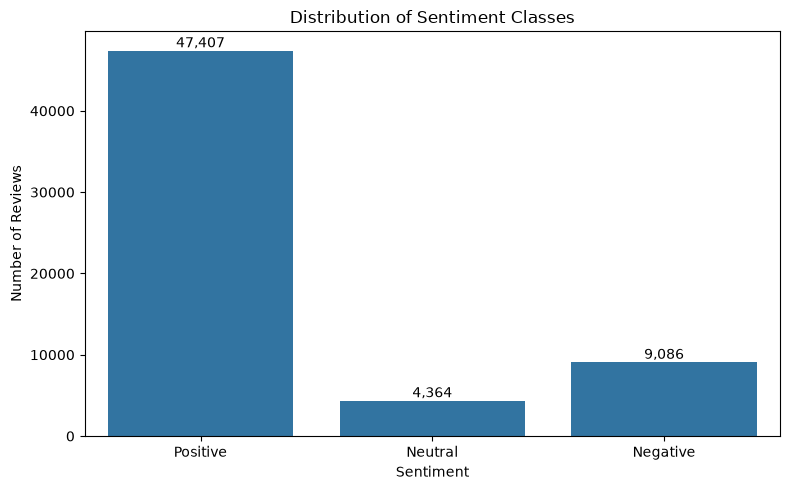

In [22]:
# Plot the sentiment distribution
sentiment_counts = model_df["sentiment"].value_counts().reindex(
    ["Positive", "Neutral", "Negative"]
)

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values,
)

plt.title("Distribution of Sentiment Classes")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

# Display counts above the bars
for bar in ax.patches:
    height = bar.get_height()
    ax.annotate(
        f"{int(height):,}",
        (bar.get_x() + bar.get_width() / 2, height),
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

In [23]:
# Display 3 examples from each sentiment class
for sentiment in ["Positive", "Neutral", "Negative"]:
    print(f"\n{'=' * 25} {sentiment} {'=' * 25}")

    examples = model_df.loc[
        model_df["sentiment"] == sentiment,
        ["review_text", "rating"]
    ].sample(
        n=3,
        random_state=42
    )

    for _, row in examples.iterrows():
        print(f"\nRating: {row['rating']}")
        print(f"Review: {row['review_text'][:700]}")


========================= Positive =========================

Rating: 5
Review: Product quality is good... Camera quality ok... Best in class battery life.. some software lag and hang issue is there... Display is too good... Speaker quality poor...

Rating: 5
Review: Nice product worth the money

Rating: 5
Review: Very good product i recently purchased it

========================= Neutral =========================

Rating: 3
Review: I want to return PANASONIC 4K UHD led

Rating: 3
Review: Good quality. High and clear volume.okaish picture quality

Rating: 3
Review: Picture quality not gud

========================= Negative =========================

Rating: 1
Review: Poor display, can't see outside

Rating: 1
Review: It is suddenly shut down

Rating: 1
Review: Fake product and used product


In [24]:
# Input: the review text
X = model_df["review_text"].copy()

# Target: the sentiment label
y = model_df["sentiment"].copy()

print("Number of reviews:", len(X))
print("Number of labels:", len(y))

print("\nExample input:")
print(X.iloc[0])

print("\nExample target:")
print(y.iloc[0])

print("\nUnique sentiment classes:")
print(sorted(y.unique()))

Number of reviews: 60857
Number of labels: 60857

Example input:
I liked it

Example target:
Positive

Unique sentiment classes:
['Negative', 'Neutral', 'Positive']


In [25]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

print("\nTraining class distribution (%):")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("percentage")
)

print("\nTesting class distribution (%):")
display(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
    .to_frame("percentage")
)

Training reviews: 48685
Testing reviews: 12172

Training class distribution (%):


,percentage
sentiment,
Positive,77.90
Negative,14.93
Neutral,7.17



Testing class distribution (%):


,percentage
sentiment,
Positive,77.90
Negative,14.93
Neutral,7.17


### Conclusion
The Amazon review dataset contains 60,889 original records. After removing 32 records with missing or empty review text, 60,857 reviews remain. Sentiment labels were validated against product ratings, and no label mismatches or duplicate review IDs were found. The dataset is imbalanced, with positive reviews representing 77.90%, negative reviews 14.93%, and neutral reviews 7.17%. A stratified 80/20 train-test split was prepared for subsequent modelling.